# Cold-target split: generalization to unseen kinases

How do the pose-aware and the no-pose model perform on kinases that are not in the training data, and how does the pose-quality prediction generalize?

**Split.** One joint split over the activity and the pose dataset. Kinase binding pockets are represented by their KLIFS pocket sequence; identical pockets (gaps ignored) are merged first (870 sequences → 382 kinase pockets), the pockets are clustered by BLOSUM sequence similarity (affinity propagation, fixed random state), and the clusters are assigned to 5 folds (GroupKFold). The held-out fold is halved by sample into validation and test, so validation and test share kinase clusters, but no kinase pocket (or pocket cluster) of a test set is in the training set of either dataset. No kinase and no kinase–ligand pair is shared between the training set of one task and the test set of the other (see `dataset_overlap.ipynb`).

**Models.** Pose-aware and no-pose model, trained with the same settings as on the scaffold split (RMSD ≤ 10 Å, ε = 0.10, pose class weights 10 / 7, seed 42); the pose-aware model is selected on the mean validation MAE of activity and pose, the no-pose model on the validation activity MAE. Activity values are in z-units of each fold (pIC50 standardized with the training mean and standard deviation of the fold, ≈ 1.29).

**Contents.** 1. checks, 2. size of the test folds, 3. activity per fold and pooled, 4. pose-quality prediction on unseen kinases, including how reliable high and low scores are.

In [1]:
from pathlib import Path
import sys

# repo root = first parent folder that contains the kinodata package
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
DATA = REPO / "analysis_publication" / "data" / "cold_target"
OUTPUT = REPO / "analysis_publication" / "output" / "cold_target"
OUTPUT.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

K_FOLDS = 5
K_SIG, X0_SIG = 0.9, 4.5     # q = 1 / (1 + exp(0.9 (RMSD - 4.5)))
MODELS = {"pose_aware": dict(label="Pose-aware", color=COLORS["pose_aware"]),
          "no_pose": dict(label="No-pose", color=COLORS["no_pose"])}
LABELS = {m: v["label"] for m, v in MODELS.items()}
COLS = {m: v["color"] for m, v in MODELS.items()}


def q_from_rmsd(r):
    return 1 / (1 + np.exp(K_SIG * (np.asarray(r, dtype=float) - X0_SIG)))


def auroc(score, positive):
    # P(score of a positive > score of a negative), ties counted half (Mann-Whitney)
    score, positive = np.asarray(score, dtype=float), np.asarray(positive, dtype=bool)
    n1 = positive.sum(); n0 = len(positive) - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = stats.rankdata(score)
    return (r[positive].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def sigma_bins(d, n_bins=10):
    # 10 equal-count bins of sigma
    s = d["sigma"].to_numpy(); sq = d["err"].to_numpy() ** 2
    b = np.clip(np.digitize(s, np.quantile(s, np.linspace(0, 1, n_bins + 1))[1:-1]), 0, n_bins - 1)
    t = pd.DataFrame({"b": b, "s": s, "sq": sq}).groupby("b").agg(n=("s", "size"), s=("s", "mean"), mse=("sq", "mean"))
    t["rmse"] = np.sqrt(t["mse"])
    return t


def ece(d, n_bins=10):
    # ECE = sum_b (n_b / N) |RMSE_b - mean sigma_b|
    t = sigma_bins(d, n_bins)
    return float((t.n / t.n.sum() * (t.rmse - t.s).abs()).sum())


def prepare(d):
    d = d.copy()
    d["sigma"] = np.sqrt(d["variance"])
    d["err"] = d["pred_activity"] - d["target_activity"]
    d["abs_err"] = d["err"].abs()
    return d


def activity_metrics(d):
    return {"MAE": d["abs_err"].mean(), "RMSE": np.sqrt((d["err"] ** 2).mean()),
            "Pearson r": stats.pearsonr(d.pred_activity, d.target_activity)[0],
            "Spearman ρ": stats.spearmanr(d.pred_activity, d.target_activity).correlation,
            "ECE": ece(d), "mean σ": d["sigma"].mean(),
            "Spearman(σ, |e|)": stats.spearmanr(d["sigma"], d["abs_err"]).correlation}


def pose_metrics(p):
    # good: true RMSD <= 2.96 A (q >= 0.8), bad: >= 6.04 A (q <= 0.2)
    good, bad = p["rmsd"] <= 2.96, p["rmsd"] >= 6.04
    gb = good | bad
    return {"pose MAE": (p.pred_pose - p.target_pose).abs().mean(),
            "pose Pearson r": stats.pearsonr(p.pred_pose, p.target_pose)[0],
            "Spearman(q, RMSD)": stats.spearmanr(p.pred_pose, p["rmsd"]).correlation,
            "AUROC good vs bad": auroc(p.loc[gb, "pred_pose"], good[gb]),
            "fraction good": good.mean(), "fraction bad": bad.mean()}


def calibration_plot(ax, pooled, labels, colors):
    # RMSE per sigma bin vs mean sigma of the bin, folds pooled; ECE in a box lower right
    lim, lines = 0, []
    for m, d in pooled.items():
        t = sigma_bins(d)
        ax.plot(t.s, t.rmse, "o-", color=colors[m], label=labels[m])
        lim = max(lim, t.s.max(), t.rmse.max())
        lines.append(f"ECE {labels[m]}: {ece(d):.3f}")
    lim = np.ceil(lim * 5) / 5
    ax.plot([0, lim], [0, lim], "--", color=COLORS["diagonal"], lw=1.5, label="y = x")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_xlabel("Mean predicted σ (z-units)"); ax.set_ylabel("RMSE (z-units)")
    ax.legend(loc="upper left")
    ax.text(0.97, 0.04, "\n".join(lines), transform=ax.transAxes, ha="right", va="bottom",
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))

## 1. Test predictions and checks

`activity_test.csv.gz`: test predictions of both models (`pred_activity`, `target_activity`, `variance` = σ² in z-units²) with the kinase pocket (`pocket_id`, merged identical pockets) and pocket cluster of each complex. `pose_test.csv.gz`: pose test predictions of the pose-aware model (`pred_pose` = predicted q, `target_pose` = q of the true RMSD to the crystal pose, `true_rmsd`). Both are in test-loader order (the last incomplete batch of 32 is dropped). Checks: both models see the same test complexes, and the pose targets equal q(true RMSD).

In [2]:
act = pd.read_csv(DATA / "activity_test.csv.gz")
pose = pd.read_csv(DATA / "pose_test.csv.gz")
counts = pd.read_csv(DATA / "split_counts.csv")
names = pd.read_csv(DATA / "pocket_names.csv").set_index("pocket_id")["kinase"]
POCKET_NAME = lambda pid: names.get(pid, f"pocket {pid}")

test = {(m, k): prepare(g.reset_index(drop=True)) for (m, k), g in act.groupby(["model", "fold"])}
test_pose = {k: g.reset_index(drop=True).assign(rmsd=lambda x: x.true_rmsd) for k, g in pose.groupby("fold")}

for k in range(K_FOLDS):
    a, b = test["pose_aware", k], test["no_pose", k]
    assert len(a) == len(b) and np.allclose(a.target_activity, b.target_activity) and (a.pocket_id == b.pocket_id).all()
    assert np.allclose(test_pose[k].target_pose, q_from_rmsd(test_pose[k].true_rmsd), atol=1e-5)
print("same test complexes in both models, pose targets = q(true RMSD): OK")

same test complexes in both models, pose targets = q(true RMSD): OK


## 2. Size of each test fold

Per fold: test complexes and poses, the number of kinase pockets and pocket clusters in the test set, and the number of kinase pockets in the activity training set. "Largest pocket" = share of the fold's activity test complexes that belong to its most frequent kinase pocket: the cold-target folds are uneven, and a few kinases can make up a large part of a fold.

In [3]:
size = []
for k in range(K_FOLDS):
    d, p = test["pose_aware", k], test_pose[k]
    c = counts[counts.fold == k].set_index(["dataset", "set"])
    top = d.pocket_id.value_counts()
    size.append({"fold": k, "activity test": len(d), "pose test": len(p),
                 "kinase pockets (activity test)": d.pocket_id.nunique(), "kinase pockets (pose test)": p.pocket_id.nunique(),
                 "pocket clusters (test)": len(set(d.cluster) | set(p.cluster)),
                 "kinase pockets (activity train)": c.loc[("activity", "train"), "kinase pockets"],
                 "largest pocket": f"{POCKET_NAME(top.index[0])} ({100 * top.iloc[0] / len(d):.0f} %)",
                 "pose test: good / bad (%)": f"{100 * (p.rmsd <= 2.96).mean():.0f} / {100 * (p.rmsd >= 6.04).mean():.0f}"})
size = pd.DataFrame(size).set_index("fold")
size.to_csv(OUTPUT / "fold_sizes.csv")
size

,activity test,pose test,kinase pockets (activity test),kinase pockets (pose test),pocket clusters (test),kinase pockets (activity train),largest pocket,pose test: good / bad (%)
fold,,,,,,,,
0,7232,11488,54,18,16,309,pocket 356 (17 %),35 / 25
1,13984,4736,75,26,18,288,JAK2 (14 %),57 / 21
2,11136,7584,80,25,19,282,SYK (13 %),50 / 33
3,14464,4256,68,19,20,296,KDR (16 %),59 / 21
4,12832,5888,72,34,19,285,BTK (11 %),44 / 32


## 3. Activity: per fold and pooled

Same test complexes in both models. ECE per fold with 10 equal-count σ bins; Spearman(σ, |e|) = how well σ ranks the errors. Paired differences over the 5 folds (with 5 folds the smallest possible two-sided Wilcoxon p is 0.0625).

In [4]:
res = pd.DataFrame([{"model": m, "fold": k, **activity_metrics(d)} for (m, k), d in test.items()])
METRICS = ["MAE", "RMSE", "Pearson r", "Spearman ρ", "ECE", "mean σ", "Spearman(σ, |e|)"]
wide = res.pivot(index="fold", columns="model", values=METRICS)

table = size[["activity test", "pose test", "kinase pockets (activity test)", "kinase pockets (pose test)"]].copy()
for c in ["MAE", "Pearson r", "ECE", "Spearman(σ, |e|)"]:
    for m in MODELS:
        table[f"{c} {LABELS[m]}"] = wide[c][m]
    table[f"{c} Δ (PA − NP)"] = wide[c]["pose_aware"] - wide[c]["no_pose"]
table.to_csv(OUTPUT / "per_fold_activity.csv")
display(table.round(3))

# better = lower MAE / RMSE / ECE, higher r / ρ / Spearman(σ, |e|)
higher = {"MAE": False, "RMSE": False, "Pearson r": True, "Spearman ρ": True, "ECE": False, "Spearman(σ, |e|)": True}
paired = []
for c, hi in higher.items():
    dlt = wide[c]["pose_aware"] - wide[c]["no_pose"]
    paired.append({"metric": c, "mean Δ (PA − NP)": dlt.mean(), "sd Δ": dlt.std(),
                   "folds pose-aware better": f"{int(((dlt > 0) if hi else (dlt < 0)).sum())}/{K_FOLDS}",
                   "paired t p": stats.ttest_rel(wide[c]["pose_aware"], wide[c]["no_pose"]).pvalue,
                   "Wilcoxon p": stats.wilcoxon(wide[c]["pose_aware"], wide[c]["no_pose"]).pvalue})
pd.DataFrame(paired).set_index("metric").round(4)

,activity test,pose test,kinase pockets (activity test),kinase pockets (pose test),MAE Pose-aware,MAE No-pose,MAE Δ (PA − NP),Pearson r Pose-aware,Pearson r No-pose,Pearson r Δ (PA − NP),ECE Pose-aware,ECE No-pose,ECE Δ (PA − NP),"Spearman(σ, |e|) Pose-aware","Spearman(σ, |e|) No-pose","Spearman(σ, |e|) Δ (PA − NP)"
fold,,,,,,,,,,,,,,,,
0,7232,11488,54,18,0.811,0.759,0.052,0.320,0.443,-0.123,0.243,0.308,-0.065,0.058,0.103,-0.045
1,13984,4736,75,26,0.797,0.774,0.023,0.305,0.340,-0.035,0.367,0.254,0.114,0.061,0.037,0.024
2,11136,7584,80,25,0.788,0.811,-0.023,0.336,0.253,0.083,0.176,0.281,-0.105,0.067,0.046,0.021
3,14464,4256,68,19,0.757,0.733,0.024,0.253,0.296,-0.042,0.224,0.294,-0.069,-0.010,0.071,-0.081
4,12832,5888,72,34,0.813,0.800,0.013,0.360,0.343,0.017,0.256,0.082,0.175,0.086,0.044,0.042


,mean Δ (PA − NP),sd Δ,folds pose-aware better,paired t p,Wilcoxon p
metric,,,,,
MAE,0.0177,0.0270,1/5,0.2170,0.3125
RMSE,0.0143,0.0393,1/5,0.4608,0.4375
Pearson r,-0.0199,0.0763,2/5,0.5912,0.6250
Spearman ρ,-0.0206,0.0734,2/5,0.5648,0.6250
ECE,0.0098,0.1257,3/5,0.8699,0.8125
"Spearman(σ, |e|)",-0.0078,0.0526,3/5,0.7563,0.8125


### Pooled over the 5 folds

All test complexes of the 5 folds together (each fold in its own z-units). The pooled MAE is the complex-weighted mean of the fold MAEs, so large folds count more than in the mean of the folds.

In [5]:
pooled = {m: pd.concat([test[m, k] for k in range(K_FOLDS)], ignore_index=True) for m in MODELS}
pooled_tab = pd.DataFrame({LABELS[m]: activity_metrics(d) for m, d in pooled.items()}).T
pooled_tab["n"] = [len(d) for d in pooled.values()]
for m in MODELS:
    pooled_tab.loc[f"mean of folds, {LABELS[m]}"] = res[res.model == m][METRICS].mean()
pooled_tab.to_csv(OUTPUT / "pooled_activity.csv")
pooled_tab.round(3)

,MAE,RMSE,Pearson r,Spearman ρ,ECE,mean σ,"Spearman(σ, |e|)",n
Pose-aware,0.791,0.980,0.314,0.298,0.259,0.720,0.049,59648.0
No-pose,0.775,0.968,0.329,0.314,0.237,0.738,0.063,59648.0
"mean of folds, Pose-aware",0.793,0.983,0.315,0.301,0.254,0.728,0.052,NaN
"mean of folds, No-pose",0.775,0.969,0.335,0.322,0.244,0.733,0.060,NaN


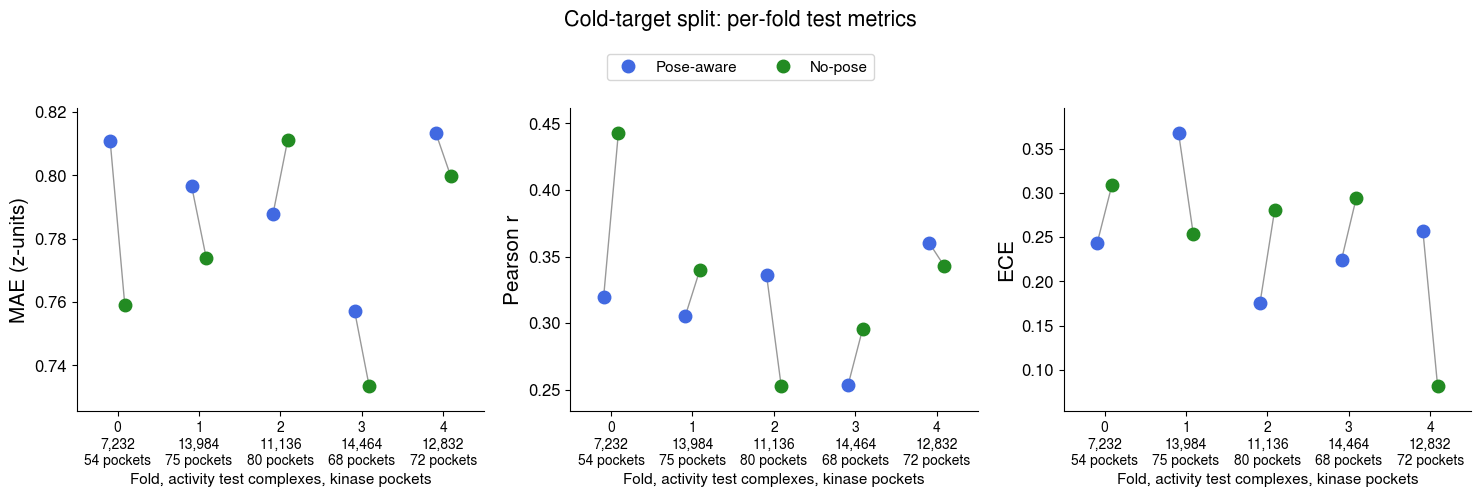

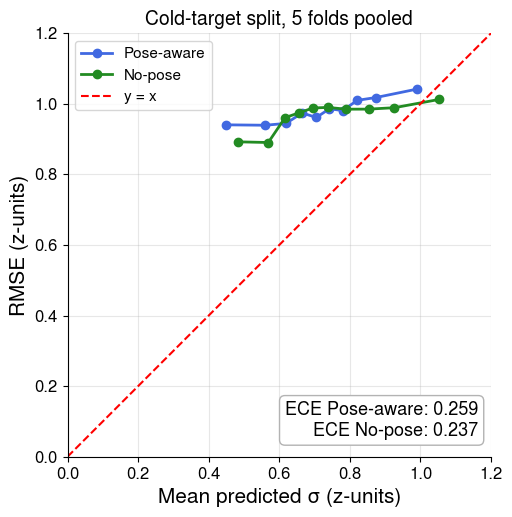

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
x = np.arange(K_FOLDS)
for ax, c in zip(axes, ["MAE", "Pearson r", "ECE"]):
    for i, m in enumerate(MODELS):
        ax.plot(x + (i - 0.5) * 0.18, wide[c][m], "o", ms=9, color=COLS[m], label=LABELS[m])
    for k in x:
        ax.plot([k - 0.09, k + 0.09], [wide[c]["pose_aware"][k], wide[c]["no_pose"][k]], color="0.6", lw=1, zorder=0)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{k}\n{size.loc[k, 'activity test']:,}\n{size.loc[k, 'kinase pockets (activity test)']} pockets" for k in x], fontsize=10)
    ax.set_xlim(-0.5, K_FOLDS - 0.5)
    ax.set_ylabel(c + (" (z-units)" if c == "MAE" else ""))
    ax.margins(y=0.1)
    ax.set_xlabel("Fold, activity test complexes, kinase pockets", fontsize=11)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Cold-target split: per-fold test metrics", y=1.08)
fig.tight_layout()
fig.savefig(OUTPUT / "per_fold_activity.png", dpi=600)
plt.show()

fig, ax = plt.subplots(figsize=(5.5, 5.5))
calibration_plot(ax, pooled, LABELS, COLS)
ax.set_title("Cold-target split, 5 folds pooled")
fig.savefig(OUTPUT / "calibration_pooled.png", dpi=600)
plt.show()

## 4. Pose-quality prediction on unseen kinases

The pose test set holds cross-docked poses of kinases that are in neither training set. The predicted q is compared with the q of the true RMSD to the crystal pose; the AUROC separates good (true RMSD ≤ 2.96 Å, q ≥ 0.8) from bad (≥ 6.04 Å, q ≤ 0.2) poses. Only the pose-aware model has a trained pose head.

,n poses,kinase pockets,pose MAE,pose Pearson r,"Spearman(q, RMSD)",AUROC good vs bad,fraction good,fraction bad
fold,,,,,,,,
0,11488.0,18.0,0.304,0.191,-0.191,0.636,0.346,0.248
1,4736.0,26.0,0.370,0.163,-0.169,0.615,0.565,0.210
2,7584.0,25.0,0.293,0.418,-0.478,0.763,0.497,0.334
3,4256.0,19.0,0.268,0.381,-0.521,0.759,0.586,0.205
4,5888.0,34.0,0.363,0.124,-0.146,0.582,0.441,0.319
pooled,33952.0,122.0,0.317,0.274,-0.306,0.671,0.457,0.269
mean of folds,6790.4,24.4,0.320,0.255,-0.301,0.671,0.487,0.263


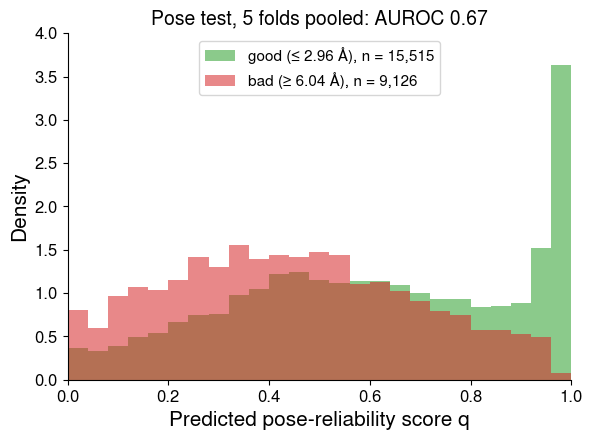

In [7]:
pose_res = pd.DataFrame([{"fold": k, "n poses": len(test_pose[k]), "kinase pockets": test_pose[k].pocket_id.nunique(),
                          **pose_metrics(test_pose[k])} for k in range(K_FOLDS)]).set_index("fold")
pp = pd.concat(test_pose.values(), ignore_index=True)
pose_res.loc["pooled"] = {"n poses": len(pp), "kinase pockets": pp.pocket_id.nunique(), **pose_metrics(pp)}
pose_res.loc["mean of folds"] = pose_res.iloc[:K_FOLDS].mean()
pose_res.to_csv(OUTPUT / "pose_head.csv")
display(pose_res.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bins = np.linspace(0, 1, 26)
for cls, sel, col in [("good (≤ 2.96 Å)", pp.rmsd <= 2.96, COLORS["good"]), ("bad (≥ 6.04 Å)", pp.rmsd >= 6.04, COLORS["bad"])]:
    ax.hist(pp.loc[sel, "pred_pose"], bins=bins, range=(0, 1), density=True, alpha=0.55, color=col, label=f"{cls}, n = {sel.sum():,}")
ax.set_xlim(0, 1)
ax.set_xlabel("Predicted pose-reliability score q"); ax.set_ylabel("Density")
ax.set_title(f"Pose test, 5 folds pooled: AUROC {pose_res.loc['pooled', 'AUROC good vs bad']:.2f}")
ax.legend(loc="upper center")
fig.savefig(OUTPUT / "pose_head_q_by_class.png", dpi=600)
plt.show()

### How reliable are high and low scores?

The histogram shows that good and bad poses overlap over most of the score range, but that nearly all poses with a very high score are good. The table gives, for poses above (or below) a score threshold, how many there are and which share of them is truly good, medium or bad, compared with the share in the whole pose test set; the second table splits the high-score poses (q ≥ 0.96) by fold, with the number of kinase pockets they come from.

In [8]:
pp["class"] = np.select([pp.rmsd <= 2.96, pp.rmsd >= 6.04], ["good", "bad"], "medium")


def class_shares(s):
    return pd.Series({"poses": len(s), "share of test poses": len(s) / len(pp),
                      "good": (s["class"] == "good").mean(), "medium": (s["class"] == "medium").mean(), "bad": (s["class"] == "bad").mean(),
                      "median true RMSD (Å)": s.rmsd.median()})


thr = pd.DataFrame({"all test poses": class_shares(pp),
                    **{f"q ≥ {t}": class_shares(pp[pp.pred_pose >= t]) for t in [0.8, 0.9, 0.96]},
                    **{f"q ≤ {t}": class_shares(pp[pp.pred_pose <= t]) for t in [0.2]}}).T
thr.to_csv(OUTPUT / "pose_score_thresholds.csv")
display(thr.round(3))

high = pp[pp.pred_pose >= 0.96]
by_fold = high.groupby("fold").agg(poses=("class", "size"), good=("class", lambda c: (c == "good").mean()),
                                   bad=("class", lambda c: (c == "bad").mean()), kinase_pockets=("pocket_id", "nunique"))
by_fold["poses in fold"] = pp.groupby("fold").size()
display(by_fold.round(3))
top = high.pocket_id.value_counts()
print(f"q ≥ 0.96: {len(high):,} poses from {high.pocket_id.nunique()} of {pp.pocket_id.nunique()} kinase pockets; "
      f"largest: {POCKET_NAME(top.index[0])} ({top.iloc[0] / len(high):.0%})")

,poses,share of test poses,good,medium,bad,median true RMSD (Å)
all test poses,33952.0,1.000,0.457,0.274,0.269,3.397
q ≥ 0.8,6668.0,0.196,0.719,0.158,0.123,1.551
q ≥ 0.9,4194.0,0.124,0.828,0.102,0.070,1.127
q ≥ 0.96,2496.0,0.074,0.903,0.087,0.011,0.742
q ≤ 0.2,4084.0,0.120,0.321,0.279,0.400,4.848


,poses,good,bad,kinase_pockets,poses in fold
fold,,,,,
0,191,0.675,0.058,11,11488
1,32,0.719,0.094,8,4736
2,1117,0.992,0.001,7,7584
3,1131,0.860,0.010,4,4256
4,25,0.800,0.040,7,5888


q ≥ 0.96: 2,496 poses from 37 of 122 kinase pockets; largest: Mouse_PKACa (43%)


## 5. Supporting Information figure

(a) Activity test MAE of both models, five folds pooled (bars) and per fold (points; lines connect the two models on the same fold). (b) Uncertainty calibration, five folds pooled, with the ECE as defined in the Methods of the paper.

In [ ]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1, 1.25]})

# (a) MAE: pooled (bars) and per fold (points, paired by fold)
x = {m: i for i, m in enumerate(MODELS)}
for m in MODELS:
    ax_a.bar(x[m], pooled_tab.loc[LABELS[m], "MAE"], width=0.55, color=COLS[m], alpha=0.85)
    ax_a.text(x[m], 0.04, f"pooled\n{pooled_tab.loc[LABELS[m], 'MAE']:.3f}", ha="center", va="bottom", color="white", fontweight="bold")
for k in range(K_FOLDS):
    ax_a.plot([x["pose_aware"], x["no_pose"]], [wide["MAE"]["pose_aware"][k], wide["MAE"]["no_pose"][k]],
              "o-", color="0.25", ms=7, lw=1, mfc="white", zorder=3)
ax_a.set_xticks(list(x.values()))
ax_a.set_xticklabels([LABELS[m] for m in MODELS])
ax_a.set_xlim(-0.6, 1.6)
ax_a.set_ylim(0, 1.0)
ax_a.set_ylabel("Activity MAE (z-units)")
ax_a.plot([], [], "o-", color="0.25", mfc="white", ms=7, lw=1, label="single fold")
ax_a.legend(loc="upper center")

# (b) calibration, folds pooled
calibration_plot(ax_b, pooled, LABELS, COLS)

for ax, lab in [(ax_a, "(a)"), (ax_b, "(b)")]:
    ax.text(-0.18, 1.04, lab, transform=ax.transAxes, fontsize=16, fontweight="bold", va="bottom")
fig.tight_layout()
fig.savefig(OUTPUT / "cold_target_si.png", dpi=600)
plt.show()